# 01 · La fitness $f$

$$
f(s) = \mathrm{depth}\big(R(Q, s)\big)
$$

$R$ est la chaîne de `fitness_inner` (`generate_preset_pass_manager(3, backend, initial_layout = s)`, sans les étapes de choix du placement). Elle fait trois choses :

1. **Traduction** des portes du circuit $Q$ dans la base de la puce : `cx`, `rz`, `sx`, `x`.
2. **Routage (Sabre)** : chaque porte à 2 qubits sur des qubits physiques non voisins ($d > 1$) est précédée de `SWAP` ; un `SWAP` vaut 3 `cx`.
3. **Optimisation** (niveau 3) : simplification des portes.

La profondeur est le nombre de couches de portes parallèles (définition au notebook 00, section 6).

**Décomposition :**

$$
f(s) = \underbrace{\mathrm{depth}(\text{circuit traduit})}_{\text{ne dépend pas de } s} + \underbrace{\text{surcoût du routage}}_{\text{dépend de } s,\ \text{et c'est lui qu'on minimise}}
$$

C'est une décomposition approximative, puisque l'optimisation agit sur l'ensemble du circuit.

In [1]:
import numpy as np
import pandas as pd

# Pont vers source.py et extraction de statistiques de circuit.
from goc import circuit_data, source_bridge
# Chargement des instances, vraie fitness, coût de distance.
from optimizer import Problem, available_instances, distance_cost, load_instance
# Outils de représentation : permutations aléatoires, échanges, conversion en placement.
from optimizer.representation import random_permutation, random_swap_indices, swap, to_mapping

# Générateur aléatoire avec graine fixe : les placements tirés sont les mêmes à chaque exécution.
rng = np.random.default_rng(0)

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## 1. Avant et après `fitness_inner`, sur l'instance 1

L'instance 1 est un circuit de Deutsch-Jozsa à 12 qubits : $q_0, \dots, q_{10}$ interagissent chacun une fois avec $q_{11}$. $G_I$ est donc une étoile $K_{1,11}$. La puce (échelle 2×8) a $\Delta_C = 3$ : au moins $11 - 3 = 8$ partenaires de $q_{11}$ sont à distance $\ge 2$, donc tout placement a $C(s) \ge 8$ : aucun placement ne rend toutes les portes directes.

On applique la chaîne de `fitness_inner` au placement identité et on compare le circuit avant et après.

In [3]:
instance = load_instance(1)

In [4]:
def describe(circuit):
    """Résumé lisible d'un circuit : qubits, profondeur, portes, portes à 2 qubits, types de portes."""
    summary = circuit_data.summary(circuit)
    counts = sorted(summary["gateCounts"].items(), key=lambda kv: -kv[1])
    return {
        "qubits": summary["numQubits"],
        "depth": summary["depth"],
        "gates": summary["size"],
        "2-qubit gates": summary["twoQubitGates"],
        "gate types": ", ".join(f"{name} {count}" for name, count in counts),
    }


# Placement identité : qubit logique i sur qubit physique i.
identity = list(range(instance.n))
# Circuit routé par la même chaîne que fitness_inner.
routed = source_bridge.routed_circuit(identity, instance.circuit, instance.backend)
# Comparaison avant / après, en texte pour un affichage homogène.
circuit_comparison = pd.DataFrame({"original circuit": describe(instance.circuit), "after fitness_inner (identity)": describe(routed)}).astype(str)
circuit_comparison

,original circuit,after fitness_inner (identity)
qubits,12,16
depth,13,57
gates,34,129
2-qubit gates,11,51
gate types,"h 14, cx 11, u2 9","cx 51, rz 49, sx 27, x 2"


**Lecture :**
- le circuit routé vit sur les $m = 16$ qubits physiques ;
- les portes sont traduites dans la base `cx`, `rz`, `sx`, `x` ;
- l'excès de `cx` provient des `SWAP` ($\approx 3$ `cx` chacun) ;
- la profondeur après routage est $f(s)$.

## 2. Toutes les instances

Une seule évaluation par placement. Deux rapports permettent de lire le tableau :
- $f(\mathrm{id}) / \mathrm{depth}(Q)$ : ce que coûtent la traduction et le routage pour le placement identité ;
- $f(\mathrm{aléatoire}) / f(\mathrm{id})$ : la sensibilité de l'instance au placement. S'il est proche de 1, le placement compte peu ; s'il est grand, l'optimisation a beaucoup à gagner.

In [5]:
rows = []
for instance_id in available_instances():
    inst = load_instance(instance_id)
    problem = Problem(inst)
    identity = list(range(inst.n))
    # Placement aléatoire : les n premiers éléments d'une permutation aléatoire de range(m).
    random_mapping = to_mapping(random_permutation(inst.m, rng), inst.n)
    rows.append({
        "instance": instance_id,
        "n": inst.n,
        "m": inst.m,
        "hardware": inst.hardware_name,
        "2q gates": inst.two_qubit_gates,
        "logical_depth": inst.logical_depth,
        # Une seule vraie évaluation de chaque placement.
        "identity_fitness": problem.fitness(identity),
        "random_fitness": problem.fitness(random_mapping),
        # Coût de distance (gratuit) des mêmes placements.
        "identity_distance_cost": distance_cost(inst, identity),
        "random_distance_cost": distance_cost(inst, random_mapping),
    })
# Tableau : une ligne par instance.
overview = pd.DataFrame(rows).set_index("instance")
# Effet du routage seul (identité / profondeur logique) et effet du placement (aléatoire / identité).
overview["identity / logical"] = (overview["identity_fitness"] / overview["logical_depth"]).round(2)
overview["random / identity"] = (overview["random_fitness"] / overview["identity_fitness"]).round(2)
overview

,n,m,hardware,2q gates,logical_depth,identity_fitness,random_fitness,identity_distance_cost,random_distance_cost,identity / logical,random / identity
instance,,,,,,,,,,,
1,12,16,custom_basis_backend,11,13,57,66,19,24,4.38,1.16
2,16,16,custom_basis_backend,150,71,59,198,0,340,0.83,3.36
3,10,16,custom_basis_backend,50,20,147,212,124,128,7.35,1.44
4,19,20,fake_20q_v1,18,19,63,53,59,26,3.32,0.84
5,12,20,fake_20q_v1,148,127,342,386,274,282,2.69,1.13
6,14,20,fake_20q_v1,28,9,98,81,56,80,10.89,0.83
7,20,27,fake_27q_pulse_v1,19,20,107,156,40,60,5.35,1.46
8,20,27,fake_27q_pulse_v1,20,5,74,60,56,88,14.80,0.81
9,25,27,fake_27q_pulse_v1,24,25,137,198,50,88,5.48,1.45


## 3. Effet du placement et bruit (instance 5)

Trois placements évalués 30 fois chacun : aléatoire, identité, et optimisé pour $C$ (3000 essais de descente sur $C$, aucune vraie évaluation). On modélise l'évaluation par

$$
f(s) = F(s) + \varepsilon_s, \qquad F(s) = \mathbb{E}[f(s)]
$$

In [6]:
def surrogate_descent(instance, permutation, steps, rng):
    """Améliore une permutation par `steps` échanges aléatoires gardés s'ils ne dégradent pas le coût de distance."""
    current = permutation.copy()
    current_cost = distance_cost(instance, current[: instance.n])
    for _ in range(steps):
        candidate = swap(current, *random_swap_indices(instance.n, instance.m, rng))
        cost = distance_cost(instance, candidate[: instance.n])
        if cost <= current_cost:
            current, current_cost = candidate, cost
    return current


instance = load_instance(5)
problem = Problem(instance)
# Les trois placements comparés.
candidates = {
    "random": to_mapping(random_permutation(instance.m, rng), instance.n),
    "identity": list(range(instance.n)),
    "distance-optimised": to_mapping(surrogate_descent(instance, random_permutation(instance.m, rng), 3000, rng), instance.n),
}
RUNS = 30
# Une ligne par évaluation : placement, son coût de distance, numéro de l'essai, fitness obtenue.
samples = pd.DataFrame([
    {"label": label, "distance_cost": distance_cost(instance, mapping), "run": run, "cost": problem.fitness(mapping)}
    for label, mapping in candidates.items()
    for run in range(RUNS)
])
# Statistiques par placement (sort=False garde l'ordre random, identity, distance-optimised).
distribution_summary = samples.groupby("label", sort=False).agg(
    distance_cost=("distance_cost", "first"),
    mean=("cost", "mean"),
    std=("cost", "std"),
    min=("cost", "min"),
    max=("cost", "max"),
).round(1)
distribution_summary

,distance_cost,mean,std,min,max
label,,,,,
random,412,388.6,16.6,357,403
identity,274,371.6,21.7,336,390
distance-optimised,107,383.3,3.9,372,388


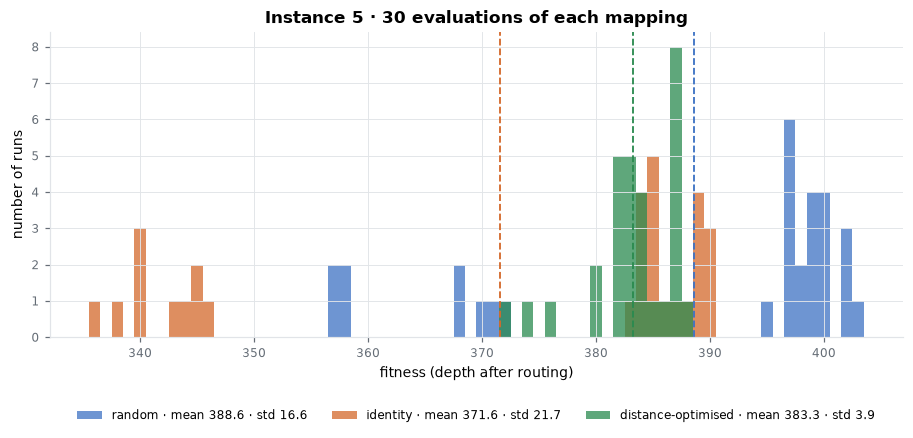

In [7]:
def plot_mapping_distributions(samples, title):
    """Histogramme des fitness obtenues pour chaque placement (une couleur par placement, moyenne en pointillés)."""
    fig, ax = plt.subplots(figsize=(10, 3.6))
    labels = list(dict.fromkeys(samples["label"]))
    # Une classe d'histogramme par valeur entière de fitness.
    bins = np.arange(samples["cost"].min() - 0.5, samples["cost"].max() + 1.5, 1)
    for color, label in zip(PALETTE, labels):
        costs = samples.loc[samples["label"] == label, "cost"]
        ax.hist(costs, bins=bins, alpha=0.75, color=color, label=f"{label} · mean {costs.mean():.1f} · std {costs.std():.1f}")
        ax.axvline(costs.mean(), color=color, linewidth=1.2, linestyle="--")
    ax.set_xlabel("fitness (depth after routing)")
    ax.set_ylabel("number of runs")
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=len(labels))
    return fig


plot_mapping_distributions(samples, "Instance 5 · 30 evaluations of each mapping");

**Interprétation :**
- **Le bruit.** $f(s)$ n'est pas une fonction déterministe : le routage Sabre fait des choix aléatoires sans graine fixée. Une évaluation est un tirage de $F(s) + \varepsilon_s$.
- **Les distributions se chevauchent.** Avec une seule évaluation, $f(s_1) < f(s_2)$ n'implique pas $F(s_1) < F(s_2)$.
- **$C$ n'est qu'une approximation.** Un petit $C(s)$ ne garantit pas un petit $F(s)$ : sur l'instance 5, le placement optimisé pour $C$ n'est pas meilleur que les autres.

Le notebook 02 quantifie ces trois effets sur toutes les instances.